In [ ]:
import os
import random
import numpy as np
import pandas as pd
import librosa
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchaudio.transforms as T
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import wandb
from tqdm import tqdm
import warnings
warnings.filterwarnings("ignore")

In [2]:
# --- Constants ---
DATA_SEED = 67
TRAINING_SEED = 1234
SR = 22050
DURATION = 5.0
N_FFT = 2048
HOP_LENGTH = 512
N_MELS = 128

In [3]:
GENRES = ['blues', 'classical', 'country', 'disco', 'hiphop',
          'jazz', 'metal', 'pop', 'reggae', 'rock']
GENRE_TO_IDX = {g: i for i, g in enumerate(GENRES)}
IDX_TO_GENRE = {i: g for g, i in GENRE_TO_IDX.items()}
STEMS = ['bass.wav', 'drums.wav', 'other.wav', 'vocals.wav']

In [4]:
DATA_ROOT = '../data/messy_mashup/genres_stems'
MODEL_DIR = '../models'
os.makedirs(MODEL_DIR, exist_ok=True)

In [5]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {DEVICE}")

Using device: cuda


In [6]:
# Reproducibility
random.seed(TRAINING_SEED)
np.random.seed(TRAINING_SEED)
torch.manual_seed(TRAINING_SEED)
torch.cuda.manual_seed(TRAINING_SEED)
torch.backends.cudnn.deterministic = True

In [7]:
# --- Dataset split (same as Milestone 1) ---
def build_song_lists(root_dir, val_split=0.17, seed=42):
    """Returns per-genre lists of song folder paths split into train/val."""
    rng = random.Random(seed)
    train_songs = {g: [] for g in GENRES}
    val_songs = {g: [] for g in GENRES}

    for genre in GENRES:
        genre_path = os.path.join(root_dir, genre)
        songs = sorted([d for d in os.listdir(genre_path)
                        if os.path.isdir(os.path.join(genre_path, d))])
        valid = []
        for song in songs:
            song_path = os.path.join(genre_path, song)
            if all(os.path.exists(os.path.join(song_path, s)) for s in STEMS):
                if not any(os.path.getsize(os.path.join(song_path, s)) < 4096 for s in STEMS):
                    valid.append(song_path)

        rng.shuffle(valid)
        n_val = int(len(valid) * val_split)
        val_songs[genre] = valid[:n_val]
        train_songs[genre] = valid[n_val:]

    return train_songs, val_songs


train_songs, val_songs = build_song_lists(DATA_ROOT)
for g in GENRES:
    print(f"{g}: train={len(train_songs[g])}, val={len(val_songs[g])}")

blues: train=83, val=17
classical: train=83, val=17
country: train=83, val=17
disco: train=83, val=17
hiphop: train=83, val=17
jazz: train=83, val=17
metal: train=83, val=17
pop: train=83, val=17
reggae: train=83, val=17
rock: train=83, val=17


In [ ]:
# --- Custom Dataset ---
class GenreDataset(Dataset):
    """Loads stems, mixes them, and converts to mel spectrogram."""

    def __init__(self, song_dict, sr=SR, duration=DURATION,
                 n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS):
        self.samples = []
        for genre, paths in song_dict.items():
            for p in paths:
                self.samples.append((p, GENRE_TO_IDX[genre]))
        self.sr = sr
        self.duration = duration
        self.n_samples = int(sr * duration)
        self.mel_transform = T.MelSpectrogram(
            sample_rate=sr, n_fft=n_fft,
            hop_length=hop_length, n_mels=n_mels
        )
        self.db_transform = T.AmplitudeToDB()

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        song_path, label = self.samples[idx]

        # Load and mix all 4 stems
        mix = np.zeros(self.n_samples, dtype=np.float32)
        for stem in STEMS:
            fp = os.path.join(song_path, stem)
            y, _ = librosa.load(fp, sr=self.sr, duration=self.duration)
            if len(y) < self.n_samples:
                y = np.pad(y, (0, self.n_samples - len(y)))
            else:
                y = y[:self.n_samples]
            mix += y

        # Peak normalize
        peak = np.max(np.abs(mix))
        if peak > 0:
            mix = mix / peak

        # Convert to mel spectrogram
        waveform = torch.tensor(mix).unsqueeze(0)  # (1, n_samples)
        mel = self.mel_transform(waveform)          # (1, n_mels, time)
        mel_db = self.db_transform(mel)             # (1, n_mels, time)

        return mel_db, label

In [ ]:
# --- CNN Model ---
class GenreCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(1, 16, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Block 2
            nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Block 3
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Block 4
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, n_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [10]:
# --- Training & Evaluation Functions ---
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    all_preds, all_labels = [], []

    for mel, labels in loader:
        mel, labels = mel.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(mel)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * mel.size(0)
        preds = outputs.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)
    epoch_acc = accuracy_score(all_labels, all_preds)
    epoch_f1 = f1_score(all_labels, all_preds, average='macro')
    return epoch_loss, epoch_acc, epoch_f1

In [ ]:
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_preds, all_labels = [], []

    for mel, labels in loader:
        mel, labels = mel.to(device), labels.to(device)
        outputs = model(mel)
        loss = criterion(outputs, labels)

        running_loss += loss.item() * mel.size(0)
        preds = outputs.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)
    epoch_acc = accuracy_score(all_labels, all_preds)
    epoch_f1 = f1_score(all_labels, all_preds, average='macro')
    return epoch_loss, epoch_acc, epoch_f1, all_preds, all_labels

In [ ]:
# --- Hyperparameters ---
BATCH_SIZE = 16
EPOCHS = 30
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

In [13]:
# --- Data Loaders ---
print("\nBuilding datasets...")
train_dataset = GenreDataset(train_songs)
val_dataset = GenreDataset(val_songs)
print(f"Train samples: {len(train_dataset)}, Val samples: {len(val_dataset)}")

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=0, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=0, pin_memory=True)


Building datasets...
Train samples: 830, Val samples: 170


In [14]:
# --- WandB Init ---
wandb.init(
    project="21f3002298-dl-genai-project",
    name="cnn-melspec-baseline",
    config={
        "model": "GenreCNN",
        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "sr": SR,
        "duration": DURATION,
        "n_fft": N_FFT,
        "hop_length": HOP_LENGTH,
        "n_mels": N_MELS,
        "optimizer": "Adam",
        "scheduler": "ReduceLROnPlateau",
        "train_size": len(train_dataset),
        "val_size": len(val_dataset),
    }
)

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from C:\Users\Atul\_netrc.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


In [15]:
# --- Model, Loss, Optimizer, Scheduler ---
model = GenreCNN(n_classes=len(GENRES)).to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5,
                                                  patience=5, verbose=True)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nModel parameters: {total_params:,} total, {trainable_params:,} trainable")
wandb.log({"total_params": total_params, "trainable_params": trainable_params})


Model parameters: 106,538 total, 106,538 trainable


In [16]:
# --- Training Loop ---
best_f1 = 0.0
best_epoch = 0

print(f"\nTraining for {EPOCHS} epochs...\n")
for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc, train_f1 = train_one_epoch(
        model, train_loader, criterion, optimizer, DEVICE)

    val_loss, val_acc, val_f1, val_preds, val_labels = evaluate(
        model, val_loader, criterion, DEVICE)

    scheduler.step(val_f1)
    current_lr = optimizer.param_groups[0]['lr']

    wandb.log({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1,
        "learning_rate": current_lr,
    })

    print(f"Epoch {epoch:02d}/{EPOCHS} | "
          f"Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} F1: {train_f1:.4f} | "
          f"Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} F1: {val_f1:.4f} | "
          f"LR: {current_lr:.6f}")

    # Save best model
    if val_f1 > best_f1:
        best_f1 = val_f1
        best_epoch = epoch
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_f1': val_f1,
            'val_acc': val_acc,
            'genres': GENRES,
            'config': {
                'sr': SR, 'duration': DURATION,
                'n_fft': N_FFT, 'hop_length': HOP_LENGTH, 'n_mels': N_MELS,
            }
        }, os.path.join(MODEL_DIR, 'cnn_best.pth'))
        print(f"  -> New best model saved (F1={val_f1:.4f})")

print(f"\nBest model: Epoch {best_epoch}, Val F1: {best_f1:.4f}")


Training for 30 epochs...

Epoch 01/30 | Train Loss: 2.0280 Acc: 0.2819 F1: 0.2274 | Val Loss: 1.8267 Acc: 0.3059 F1: 0.2466 | LR: 0.001000
  -> New best model saved (F1=0.2466)
Epoch 02/30 | Train Loss: 1.6634 Acc: 0.4036 F1: 0.3630 | Val Loss: 1.9714 Acc: 0.2824 F1: 0.2320 | LR: 0.001000
Epoch 03/30 | Train Loss: 1.5836 Acc: 0.4181 F1: 0.3934 | Val Loss: 1.6890 Acc: 0.4000 F1: 0.3347 | LR: 0.001000
  -> New best model saved (F1=0.3347)
Epoch 04/30 | Train Loss: 1.4890 Acc: 0.4602 F1: 0.4345 | Val Loss: 1.5605 Acc: 0.4000 F1: 0.3340 | LR: 0.001000
Epoch 05/30 | Train Loss: 1.3788 Acc: 0.4904 F1: 0.4741 | Val Loss: 1.3957 Acc: 0.4941 F1: 0.4528 | LR: 0.001000
  -> New best model saved (F1=0.4528)
Epoch 06/30 | Train Loss: 1.2619 Acc: 0.5386 F1: 0.5218 | Val Loss: 2.6160 Acc: 0.2824 F1: 0.2134 | LR: 0.001000
Epoch 07/30 | Train Loss: 1.2212 Acc: 0.5578 F1: 0.5431 | Val Loss: 1.9333 Acc: 0.3765 F1: 0.3348 | LR: 0.001000
Epoch 08/30 | Train Loss: 1.2203 Acc: 0.5723 F1: 0.5630 | Val Loss:

In [17]:
# --- Final Evaluation on Best Model ---
checkpoint = torch.load(os.path.join(MODEL_DIR, 'cnn_best.pth'), map_location=DEVICE)
model.load_state_dict(checkpoint['model_state_dict'])
val_loss, val_acc, val_f1, val_preds, val_labels = evaluate(
    model, val_loader, criterion, DEVICE)

pred_genres = [IDX_TO_GENRE[p] for p in val_preds]
true_genres = [IDX_TO_GENRE[l] for l in val_labels]
cr = classification_report(true_genres, pred_genres, labels=GENRES)
print(f"\nFinal Evaluation (Best Model):")
print(f"Val Accuracy: {val_acc:.4f}, Val Macro F1: {val_f1:.4f}\n")
print(cr)


Final Evaluation (Best Model):
Val Accuracy: 0.7353, Val Macro F1: 0.7271

              precision    recall  f1-score   support

       blues       0.78      0.82      0.80        17
   classical       1.00      0.82      0.90        17
     country       1.00      0.47      0.64        17
       disco       0.73      0.94      0.82        17
      hiphop       0.67      0.82      0.74        17
        jazz       0.61      0.82      0.70        17
       metal       0.79      0.88      0.83        17
         pop       0.77      0.59      0.67        17
      reggae       0.70      0.82      0.76        17
        rock       0.50      0.35      0.41        17

    accuracy                           0.74       170
   macro avg       0.75      0.74      0.73       170
weighted avg       0.75      0.74      0.73       170



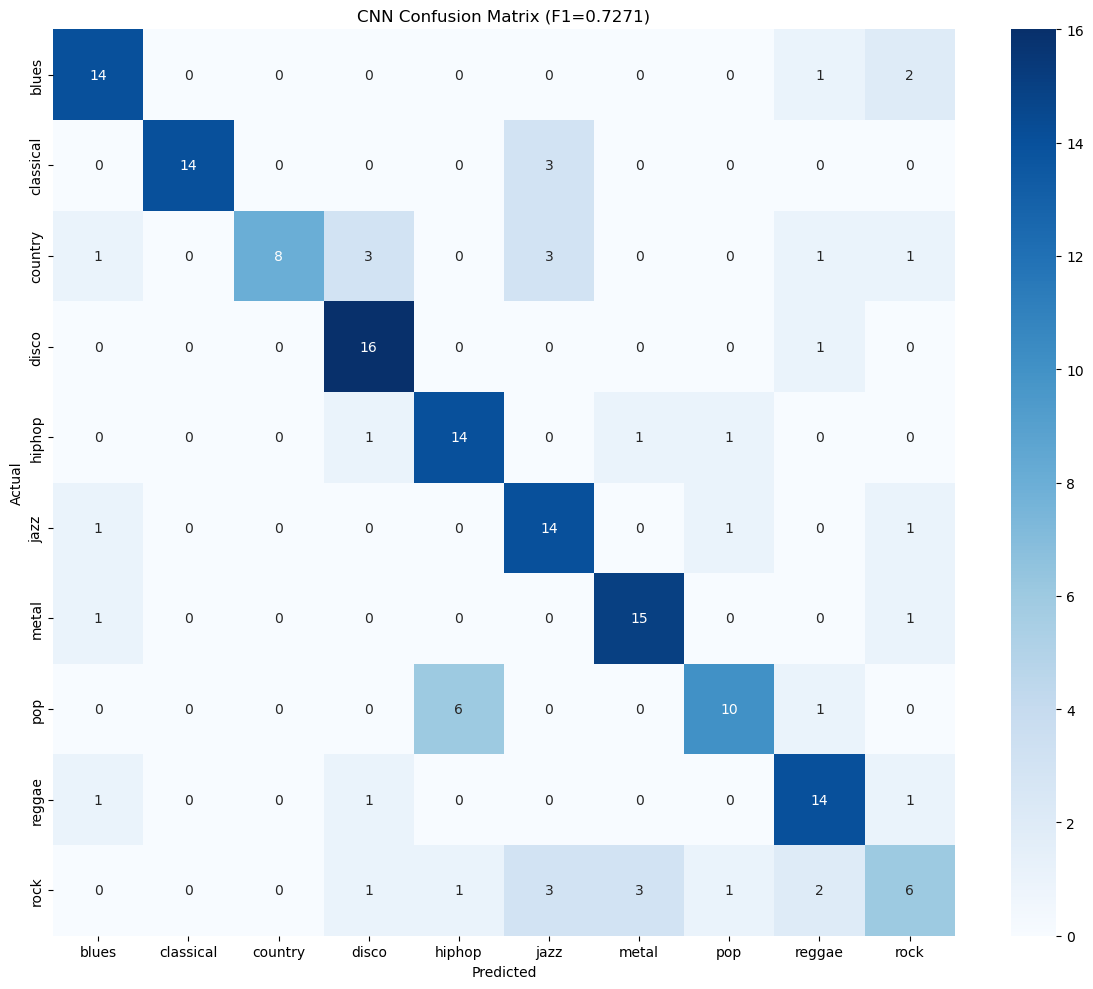

In [18]:
# Confusion matrix
cm = confusion_matrix(true_genres, pred_genres, labels=GENRES)
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=GENRES, yticklabels=GENRES, ax=ax)
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title(f'CNN Confusion Matrix (F1={val_f1:.4f})')
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, 'cnn_confusion_matrix.png'), dpi=150)
wandb.log({"confusion_matrix": wandb.Image(fig)})
plt.show()

In [19]:
# Log model artifact
artifact = wandb.Artifact('cnn-melspec-baseline', type='model')
artifact.add_file(os.path.join(MODEL_DIR, 'cnn_best.pth'))
wandb.log_artifact(artifact)

<Artifact cnn-melspec-baseline>

In [20]:
# Training complete. WandB finish.
wandb.finish()

epoch,▁▁▁▂▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇███
learning_rate,████████████████████████████▁▁
total_params,▁
train_accuracy,▁▃▃▃▄▅▅▅▅▆▅▆▆▆▆▇▆▇▇▇▇▇▇██▇████
train_loss,█▆▆▅▅▄▄▄▄▃▃▃▃▃▃▃▃▂▂▂▂▂▂▁▂▂▁▁▁▁
train_macro_f1,▁▃▃▄▄▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇▇▇▇██▇████
trainable_params,▁
val_accuracy,▁▁▃▃▄▁▂▃▄▃▄▆▄▅▆▆▅▆▅▇▆▄▇▆▇▅▅▆▇█
val_loss,▅▅▄▄▃█▅▄▃▄▃▂▃▂▂▃▃▂▃▂▃▄▁▂▂▃▅▃▂▁
val_macro_f1,▁▁▃▃▄▁▃▃▅▃▄▆▄▆▆▅▅▆▆▇▆▄▇▇▇▅▅▆▇█
epoch,30


## The End